# 6. Credit Risk Scoring with Decision Trees and Ensembles

**A beginner-friendly walkthrough: from one handwritten if/else rule to a single decision tree, a random forest, and a gradient-boosted model.**

This notebook follows the story of Module 6 of Machine Learning Zoomcamp, using the
Credit Scoring dataset. The code is a `scikit-learn` rewrite: same data, same ideas,
cleaner implementations. Every section is written for someone seeing trees for the
first time.

### How each section is organized

1. **The idea** — the concept in plain language, with an analogy where it helps.
2. **The code** — the smallest piece of code that makes the idea concrete.
3. **The result** — what the numbers or the picture say.
4. **The why** — what is really going on, and what can go wrong.

Read the explanation *before* running the cell, then compare the output with what
the text predicted. The notebook is meant to be read top to bottom: later cells
reuse variables from earlier ones.

### The question we are answering

A bank receives a loan application. The applicant will either **repay** the loan
(`ok`) or **default** on it (`default`). We want a model that estimates the
probability of default from the applicant's profile, so the bank can approve,
decline, or ask for more information.

This is a **binary classification** problem: two possible answers.

### Why decision trees?

A decision tree is a model that learns a set of **if/else questions** from data:

```text
Is records = yes?
├── yes: Is job = parttime?
│         ├── yes: default
│         └── no:  ok
└── no:  Are assets > 6000?
          ├── yes: ok
          └── no:  default
```

That looks like something a human credit analyst would write. Trees are popular
because they are:

- **interpretable** — you can print the rules and follow them;
- **non-linear** — they can capture thresholds and interactions without you
  specifying them;
- **happy with mixed data** — numeric and categorical features, no scaling needed;
- **the building block** for the strongest tabular models: random forests and
  gradient boosting.

The catch is that a single tree is easy to overfit and not very accurate on its own.
The rest of the notebook is about fixing that with **ensembles** — many trees
working together.

### The road map

| Section | Question |
|---|---|
| 1–2 | What does the data look like, and how do we clean it? |
| 3 | How do we split the data honestly? |
| 4 | How good is a handwritten rule? |
| 5 | How do we train and read a decision tree? |
| 6 | How does a tree *learn* a split? (Gini, impurity, recursion) |
| 7 | How do we stop a tree from overfitting? |
| 8–9 | Why do many trees beat one? (bagging, random forest) |
| 10–11 | How does learning from mistakes work? (gradient boosting) |
| 12 | How do we pick a final model and test it once? |
| 13 | How do we turn a probability into a business decision? |
| 14–15 | Summary, exercises, and references |

### A note on the metric

The positive class is **default** (the thing we want to catch). The main metric in
this notebook is **ROC AUC**. It measures how well a model *ranks* applicants: if
you pick one future defaulter and one future repayer at random, AUC is the
probability that the model gives the defaulter the higher risk score.

- AUC `0.5` = random ranking (useless).
- AUC `1.0` = every defaulter ranked above every repayer (perfect).
- AUC is **threshold-free**: it judges the ranking before we decide where to draw
  the approve/decline line.

To make that concrete, every threshold produces a 2×2 **confusion matrix**:

|  | predicted ok | predicted default |
|---|---:|---:|
| **actual ok** | TN (true negative) | FP (false positive) |
| **actual default** | FN (false negative) | TP (true positive) |

From those four counts:

- **True positive rate (TPR), also called recall** = `TP / (TP + FN)`: of the real
  defaulters, how many did we catch?
- **False positive rate (FPR)** = `FP / (FP + TN)`: of the good clients, how many did
  we wrongly flag?
- **Precision** = `TP / (TP + FP)`: of the clients we flagged, how many really
  defaulted?

The **ROC curve** plots TPR (y-axis) against FPR (x-axis) as the threshold moves from
1 down to 0. AUC is the area under that curve, so it summarizes ranking quality over
*all* thresholds at once. Later we will use precision, recall, and cost when we
finally pick **one** threshold.

Accuracy would be a poor guide here because only about 28% of clients default. A
model that says "everyone is fine" is already ~72% accurate while being completely
useless. You will see this concretely in Section 4.

## 1. The data

The dataset comes from Gaston Sanchez's *Credit Scoring* project, which is itself
based on a data-mining course by Tomas Aluja. It contains **4,455 rows** and
**14 columns**; one row is one applicant. One row has an unknown label, so
**4,454 rows** remain for modeling.

| Column | Meaning |
|---|---|
| `status` | **target**: `ok` (repaid) or `default` (did not repay) |
| `seniority` | years at the current job |
| `home` | home ownership: rent, owner, private, ignore, parents, other |
| `time` | time of the requested loan |
| `age` | age in years |
| `marital` | marital status: single, married, widow, separated, divorced |
| `records` | whether the client has credit records (`yes` / `no`) |
| `job` | job type: fixed, part-time, freelance, other |
| `expenses` | expenses |
| `income` | income |
| `assets` | assets |
| `debt` | debt |
| `amount` | amount of the loan requested |
| `price` | price of the good being financed |

> **About the units.** Income, assets, debt, expenses, amount, and price are stored
> in anonymized/normalized units, not dollars. Do not read `income = 120` as "$120".
> What matters is the *relative* size and the ordering.

The dataset is small, clean, and deliberately simple — ideal for learning how the
algorithms work before worrying about messy production data.

### Setup

We need four kinds of tools:

| Library | What we use it for |
|---|---|
| `pandas` | loading and manipulating the table |
| `numpy` | arrays and small numeric helpers |
| `matplotlib` / `seaborn` | plots and the heatmap |
| `scikit-learn` | splitting, encoding, models, metrics |

The imports below are the whole toolkit for the notebook. We also fix a few plotting
defaults so every figure is readable, and define `RANDOM_STATE = 11` so that the
data split is exactly the same every time you run the notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
)
from sklearn.inspection import permutation_importance

# Make tables and plots easier to read
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

RANDOM_STATE = 11

> **Two seeds, both fixed.** `RANDOM_STATE = 11` controls the train/validation/test
> split. The models below use `random_state=1` for their own randomness — feature
> subsampling in the forest, tie-breaking in the trees. Both seeds are fixed so the
> notebook is reproducible; they do not have to be the same number.

### Load the table

The CSV lives in the repository's `data/` folder, so the notebook works offline.
The course notebook downloads the same file from GitHub; the contents are identical.

In [2]:
DATA_PATH = "../data/credit_scoring.csv"

df = pd.read_csv(DATA_PATH)

print("rows, columns:", df.shape)
df.head()

rows, columns: (4455, 14)


,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


`df.head()` shows the first five rows. Notice that most columns are **integer
codes**, not words: `home = 1`, `marital = 2`, `job = 3`. Those codes are labels,
not quantities. We will translate them in a moment.

Let us look at the column types and at a few summary statistics. The summary is
especially useful for spotting impossible values.

In [3]:
df.dtypes

Status       int64
Seniority    int64
Home         int64
Time         int64
Age          int64
Marital      int64
Records      int64
Job          int64
Expenses     int64
Income       int64
Assets       int64
Debt         int64
Amount       int64
Price        int64
dtype: object

In [4]:
df[["Age", "Seniority", "Time", "Income", "Assets", "Debt", "Amount", "Price"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
Age,4455.0,37.1,11.0,18.0,28.0,36.0,45.0,68.0
Seniority,4455.0,8.0,8.2,0.0,2.0,5.0,12.0,48.0
Time,4455.0,46.4,14.7,6.0,36.0,48.0,60.0,72.0
Income,4455.0,763317.0,8703625.3,0.0,80.0,120.0,166.0,99999999.0
Assets,4455.0,1060340.8,10217568.7,0.0,0.0,3500.0,6000.0,99999999.0
Debt,4455.0,404382.0,6344253.4,0.0,0.0,0.0,0.0,99999999.0
Amount,4455.0,1039.0,474.5,100.0,700.0,1000.0,1300.0,5000.0
Price,4455.0,1462.9,628.1,105.0,1117.5,1400.0,1692.0,11140.0


Look at the **maximum** of `income`, `assets`, and `debt`: `99,999,999`. That is not
a real value. It is a **sentinel** — a placeholder the data collector used for
"unknown". If we leave it in, the model will think some clients are billionaires.

This is a very common real-world pattern: missing values are not always `NaN`.
Sometimes they are `-1`, `999`, `"N/A"`, or `99,999,999`. Always inspect the
summary statistics before modeling.

## 2. Cleaning the data

We will make five changes, in this order:

1. lowercase the column names;
2. translate the numeric codes into readable labels;
3. replace the `99,999,999` sentinel with a real missing value (`NaN`);
4. drop the one row whose status is unknown;
5. check the class balance and duplicates.

Order matters. For example, we translate `status` *before* dropping unknown rows,
so that we can see the unknown category and drop it by name instead of by a magic
number.

### 2.1 Consistent column names

`Status`, `Home`, `Job` become `status`, `home`, `job`. This avoids bugs later when
one cell says `df.Status` and another says `df.status`. It is a small habit that
saves a lot of debugging.

In [5]:
df.columns = df.columns.str.lower()
df.columns.tolist()

['status',
 'seniority',
 'home',
 'time',
 'age',
 'marital',
 'records',
 'job',
 'expenses',
 'income',
 'assets',
 'debt',
 'amount',
 'price']

### 2.2 Translate the codes

The codebook from the dataset author is:

| Column | Code → label |
|---|---|
| `status` | `1 → ok`, `2 → default`, `0 → unk` |
| `home` | `1 → rent`, `2 → owner`, `3 → private`, `4 → ignore`, `5 → parents`, `6 → other`, `0 → unk` |
| `marital` | `1 → single`, `2 → married`, `3 → widow`, `4 → separated`, `5 → divorced`, `0 → unk` |
| `records` | `1 → no`, `2 → yes`, `0 → unk` |
| `job` | `1 → fixed`, `2 → parttime`, `3 → freelance`, `4 → others`, `0 → unk` |

Let us first confirm the raw counts, then apply the mapping.

In [6]:
df["status"].value_counts().sort_index()

status
0       1
1    3200
2    1254
Name: count, dtype: int64

In [7]:
status_values = {1: "ok", 2: "default", 0: "unk"}
home_values = {
    1: "rent", 2: "owner", 3: "private", 4: "ignore",
    5: "parents", 6: "other", 0: "unk",
}
marital_values = {
    1: "single", 2: "married", 3: "widow", 4: "separated",
    5: "divorced", 0: "unk",
}
records_values = {1: "no", 2: "yes", 0: "unk"}
job_values = {1: "fixed", 2: "parttime", 3: "freelance", 4: "others", 0: "unk"}

df["status"] = df["status"].map(status_values)
df["home"] = df["home"].map(home_values)
df["marital"] = df["marital"].map(marital_values)
df["records"] = df["records"].map(records_values)
df["job"] = df["job"].map(job_values)

df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


Now the table is readable. But there is a deeper reason to translate the codes:
**a tree must not be allowed to think that `home = 3` is "more" than `home = 1`.**
If we leave the integers in place, a tree can create a split such as
`home <= 1.5`, which mixes "rent" and "owner" for no real-world reason. The order
1, 2, 3 is arbitrary; it is only a filing system.

After translation we will **one-hot encode** the categories, so the model sees
"is this rent?", "is this owner?", etc. as separate yes/no questions. That removes
the fake ordering.

> **A typo worth knowing about.** The original course code maps job code 2 to
> `"partime"` but its handwritten rule tests for `"parttime"`. The two spellings
> never match, so one branch of the rule is dead code. Here we use `"parttime"`
> consistently, and the rule below actually does what it says.

### 2.3 Turn the sentinel into a real missing value

`99,999,999` means "unknown", so we replace it with `NaN` (Not a Number), pandas'
standard missing-value marker. Then `isna().sum()` tells us how many values are
missing in each column.

In [8]:
for col in ["income", "assets", "debt"]:
    df[col] = df[col].replace(99_999_999.0, np.nan)

df[["income", "assets", "debt"]].isna().sum()

income    34
assets    47
debt      18
dtype: int64

There are only **99 missing values** in total (34 income, 47 assets, 18 debt). Why
not replace them with `0` right away?

- For **income**, `0` is a meaningful value (no income). Replacing "unknown" with
  `0` teaches the model that a missing income is the same as no income. That is a
  different claim.
- For **assets** and **debt**, `0` is extremely common already (the median debt is
  `0`), so `0` is less unreasonable — but it is still a guess.
- A tree cannot handle `NaN` at all; it needs a number. So *some* choice is
  required.

In this notebook we follow the course and fill with `0` before encoding. That is
simple and works well enough here, but it is a modeling decision, not a law of
nature. Section 15's exercises ask you to try a better option: fill with the
training median and add a "was missing" indicator column.

### 2.4 Drop the unknown status

There is only one row with `status = "unk"`. It has no label, so it cannot be used
for supervised learning. We drop it and reset the index so the rows are numbered
`0..n-1` again.

In [9]:
df = df[df["status"] != "unk"].reset_index(drop=True)

print("rows after dropping unknown status:", len(df))
print("duplicate rows:", df.duplicated().sum())

df["status"].value_counts()

rows after dropping unknown status: 4454
duplicate rows: 2


status
ok         3200
default    1254
Name: count, dtype: int64

Two rows are exact duplicates. We keep them: in a credit dataset, two different
people can genuinely have the same age, job, income, and loan request. Dropping
them would throw away real applicants. (Duplicate *IDs* would be a different
story — but this dataset has no ID column.)

### 2.5 Class balance

The target is imbalanced: roughly 28% default, 72% repaid. This single fact drives
almost every metric decision in the notebook, so let us quantify it.

In [10]:
class_share = df["status"].value_counts(normalize=True).round(3)
print(class_share)

majority_accuracy = class_share.max()
print(f"\n'always ok' accuracy: {majority_accuracy:.3f}")
print(f"'always ok' ROC AUC:  0.500  (a constant score cannot rank anyone)")

status
ok         0.718
default    0.282
Name: proportion, dtype: float64

'always ok' accuracy: 0.718
'always ok' ROC AUC:  0.500  (a constant score cannot rank anyone)


This is the **accuracy trap**. A lazy model that predicts `ok` for every applicant
scores **~0.72 accuracy** while catching **zero** defaulters. If you report only
accuracy, that model looks respectable. ROC AUC gives it `0.5`, correctly calling
it useless.

We will use **ROC AUC for model selection** (it is threshold-free and ranking-based)
and then, at the very end, choose a **threshold** based on the real cost of mistakes.

## 3. Split: train, validation, test

If we evaluate a model on the same rows it learned from, it will look better than it
really is — like grading a student on the exact homework problems they just
memorized. We therefore hold data out.

| Set | Share | Purpose |
|---|---|---|
| **train** | 60% | the model learns from these rows |
| **validation** | 20% | we compare models and tune hyperparameters here |
| **test** | 20% | touched **once**, at the very end, for an honest estimate |

A useful analogy: train = homework, validation = practice exams, test = the final
exam. You may look at practice-exam results and change your study plan; you may not
peek at the final exam while studying.

We get 60/20/20 by calling `train_test_split` twice:

1. carve off 20% for test;
2. carve 25% of the remaining 80% for validation — that is 20% of the original.

Using `random_state=11` makes the split reproducible: everyone who runs this
notebook gets the same rows in each set.

In [11]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE
)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=RANDOM_STATE
)

# Clean 0..n-1 indexes in every split
for part in (df_train, df_val, df_test, df_full_train):
    part.reset_index(drop=True, inplace=True)

print("train:", len(df_train))
print("validation:", len(df_val))
print("test:", len(df_test))
print("train + validation:", len(df_full_train))

train: 2672
validation: 891
test: 891
train + validation: 3563


The sizes are **2,672 / 891 / 891** rows. The exact split is random, so the default
rate is not identical in each set — that is normal sampling noise, and it is one
reason we later use cross-validation as a second opinion.

### Separate the target from the features

We copy the labels into `y` **before** deleting `status` from the feature tables.
If `status` stayed in `X`, the model could read the answer directly. That mistake is
called **leakage**, and it produces beautiful, meaningless scores.

In [12]:
y_train = (df_train["status"] == "default").astype(int).values
y_val = (df_val["status"] == "default").astype(int).values
y_test = (df_test["status"] == "default").astype(int).values
y_full_train = (df_full_train["status"] == "default").astype(int).values

# Features = everything except the target
del df_train["status"]
del df_val["status"]
del df_test["status"]
# df_full_train keeps status for the final refit in Section 12

print("train default rate:", round(y_train.mean(), 3))
print("validation default rate:", round(y_val.mean(), 3))
print("test default rate:", round(y_test.mean(), 3))

train default rate: 0.274
validation default rate: 0.295
test default rate: 0.291


> **Seal the test set.** From here until Section 12 we do not touch `df_test` or
> `y_test`. Every comparison happens on validation data. If we tuned on test, the
> final number would be optimistic — we would have used the exam to study.

## 4. Baseline: a handwritten rule

Before training anything, let us write the rule from the introduction by hand and
measure it. This gives us a baseline and, more importantly, shows *why* learning
from data is worth the effort.

The rule:

- if the client has credit `records = yes`:
  - and the job is `parttime` → predict `default`;
  - otherwise → predict `ok`;
- if the client has no records:
  - and `assets > 6000` → predict `ok`;
  - otherwise → predict `default`.

In [13]:
def assess_risk(client):
    # A human-written credit rule. Returns 'default' or 'ok'.
    if client["records"] == "yes":
        if client["job"] == "parttime":
            return "default"
        return "ok"
    else:
        if client["assets"] > 6000:
            return "ok"
        return "default"


client = df_train.iloc[0].to_dict()
print("client features:")
for key, value in client.items():
    print(f"  {key:>10}: {value}")

print("\nrule says:  ", assess_risk(client))
print("actual label:", "default" if y_train[0] == 1 else "ok")

client features:
   seniority: 10
        home: owner
        time: 36
         age: 36
     marital: married
     records: no
         job: freelance
    expenses: 75
      income: 0.0
      assets: 10000.0
        debt: 0.0
      amount: 1000
       price: 1400

rule says:   ok
actual label: default


Already we catch a problem: this client actually defaulted, but the rule says `ok`.
One example proves nothing, so let us score the rule on the whole validation set.
We will count how often it is right and build its confusion matrix.

In [14]:
rule_pred = np.array([
    1 if assess_risk(row) == "default" else 0
    for row in df_val.to_dict(orient="records")
])

rule_acc = accuracy_score(y_val, rule_pred)
rule_auc = roc_auc_score(y_val, rule_pred)
cm = confusion_matrix(y_val, rule_pred)
tn, fp, fn, tp = cm.ravel()

print(f"rule accuracy:       {rule_acc:.3f}")
print(f"'always ok' accuracy:{1 - y_val.mean():.3f}")
print(f"rule ROC AUC:        {rule_auc:.3f}")
print(f"\nconfusion matrix [[TN, FP], [FN, TP]]:\n{cm}")
print(f"flagged as default:  {rule_pred.mean():.1%} of clients")
print(f"actually default:    {y_val.mean():.1%} of clients")

rule accuracy:       0.416
'always ok' accuracy:0.705
rule ROC AUC:        0.471

confusion matrix [[TN, FP], [FN, TP]]:
[[212 416]
 [104 159]]
flagged as default:  64.5% of clients
actually default:    29.5% of clients


**The handwritten rule scores 0.42 accuracy — worse than always saying "ok" (0.70).**
It also flags 65% of applicants as defaulters when only 30% actually default. The
rule is not "slightly off"; it is systematically too pessimistic, because the
threshold `assets > 6000` was invented rather than learned.

This is the key lesson of the section:

- A rule that *sounds* sensible can be badly calibrated.
- Accuracy alone cannot tell you whether a rule is useful.
- The AUC of a binary rule is `(recall + specificity) / 2`; here it is about `0.47`,
  i.e. slightly worse than a coin flip at ranking.

So instead of guessing the thresholds, let the data choose them. That is exactly
what a decision tree does.

## 5. A decision tree in scikit-learn

A tree needs a **numeric matrix** `X`, one column per feature. Our table has text
columns (`home`, `job`, …), so we must encode them.

`DictVectorizer` does two things:

- **numeric columns pass through unchanged**;
- **string columns become one-hot columns**: `home=rent` is a new 0/1 column that is
  1 when the client rents and 0 otherwise.

One-hot encoding is important: it lets the tree ask "is this person a renter?"
without pretending that `rent < owner < private` is a meaningful order.

> **Why `fillna(0)`?** `DictVectorizer` and scikit-learn's trees do not accept
> `NaN`. We replace missing numbers with `0` as a simple sentinel. The categorical
> columns have no missing values after translation. As noted in Section 2, this is a
> pragmatic choice; a median imputer plus a missingness flag is often better.

In [15]:
train_dicts = df_train.fillna(0).to_dict(orient="records")
val_dicts = df_val.fillna(0).to_dict(orient="records")

dv = DictVectorizer(sparse=False)

# Fit the encoder on TRAIN only, then reuse it for validation/test.
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print("X_train shape:", X_train.shape)
print("number of encoded features:", len(dv.get_feature_names_out()))
print("\nfirst 12 feature names:")
for name in list(dv.get_feature_names_out())[:12]:
    print(" ", name)

X_train shape: (2672, 29)
number of encoded features: 29

first 12 feature names:
  age
  amount
  assets
  debt
  expenses
  home=ignore
  home=other
  home=owner
  home=parents
  home=private
  home=rent
  home=unk


There are **29 encoded columns** from 13 original features. The **9 numeric columns**
stay as they are. The 4 categorical features expand into **20 one-hot columns**:
`home` 7, `marital` 6, `records` 2 (`no`/`yes`), and `job` 5. The matrix is **dense**
(`sparse=False`) because it is small enough; for millions of rows you would keep it
sparse.

### 5.1 An unrestricted tree: watch it memorize

First, let us fit a tree with no limits. `DecisionTreeClassifier()` will keep
splitting until every leaf is pure or until it runs out of sensible splits.

In [16]:
dt_full = DecisionTreeClassifier(random_state=1)
dt_full.fit(X_train, y_train)

train_auc_full = roc_auc_score(y_train, dt_full.predict_proba(X_train)[:, 1])
val_auc_full = roc_auc_score(y_val, dt_full.predict_proba(X_val)[:, 1])

print(f"tree depth:  {dt_full.get_depth()}")
print(f"tree leaves: {dt_full.get_n_leaves()}")
print(f"train AUC:   {train_auc_full:.3f}")
print(f"val AUC:     {val_auc_full:.3f}")

tree depth:  20
tree leaves: 451
train AUC:   1.000
val AUC:     0.650


The tree has **451 leaves** and reaches **train AUC = 1.000**. A perfect training
score is a warning sign, not a success: the tree has carved the training data into
tiny groups, and within each group it can perfectly separate the labels. On unseen
validation data it drops to about **0.65** — far below the tuned tree we build
later.

This is **overfitting**: the model learned the noise in the training set, not the
pattern that generalizes.

### 5.2 A shallow tree: readable but too simple

Now limit the tree to depth 2. Depth = the maximum number of splits on any path from
root to leaf. Depth 2 allows at most 4 leaves, so the model can only ask two
questions in a row.

In [17]:
dt2 = DecisionTreeClassifier(max_depth=2, random_state=1)
dt2.fit(X_train, y_train)

train_auc_2 = roc_auc_score(y_train, dt2.predict_proba(X_train)[:, 1])
val_auc_2 = roc_auc_score(y_val, dt2.predict_proba(X_val)[:, 1])

print(f"train AUC: {train_auc_2:.3f}")
print(f"val AUC:   {val_auc_2:.3f}")

train AUC: 0.705
val AUC:   0.669


In [18]:
tree_text = export_text(dt2, feature_names=list(dv.get_feature_names_out()))
print(tree_text)

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- class: 0
|--- records=no >  0.50
|   |--- job=parttime <= 0.50
|   |   |--- class: 0
|   |--- job=parttime >  0.50
|   |   |--- class: 1



**How to read this output**

```text
|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- class: 1
```

- `records=no` is a **one-hot column**: it is 1 for clients with no credit records
  and 0 otherwise. The test `records=no <= 0.50` is true when the column is 0, so
  the left branch means the client is **not** in the `records=no` group — they have
  `records=yes`. This is the awkward part of reading trees after one-hot encoding:
  the column name is the *positive* category, and a `<= 0.5` test sends the
  *negative* category to the left.
- `seniority <= 6.50` is a numeric split: job seniority of 6.5 years or less.
- `class: 1` means the majority of training clients in that leaf defaulted.
  The leaf stores a **probability**, not just the class; `predict_proba` returns the
  proportion of defaulters in the leaf.

So the top-left path reads:

> If the client has credit records **and** job seniority ≤ 6.5 years → predict
> **default**.

and the bottom-right path reads:

> If the client has **no** credit records **and** is a part-timer → predict
> **default**.

Some of these rules may look counterintuitive (part-timers with no records being
risky). With only four leaves, the tree is forced to summarize a lot of people with
one number. A shallow tree has **high bias**: it is too simple to capture the real
pattern. Its validation AUC (~0.67) is better than the handwritten rule but far from
what is achievable.

### 5.3 What `predict` and `predict_proba` return

It is worth seeing the difference concretely:

In [19]:
sample = X_val[:5]

print("predicted class (0 = ok, 1 = default):", dt2.predict(sample))
print("predicted probabilities [P(ok), P(default)]:")
print(np.round(dt2.predict_proba(sample), 3))

predicted class (0 = ok, 1 = default): [0 0 0 0 0]
predicted probabilities [P(ok), P(default)]:
[[0.83  0.17 ]
 [0.83  0.17 ]
 [0.619 0.381]
 [0.83  0.17 ]
 [0.83  0.17 ]]


For each row, the two probabilities sum to 1. `predict()` simply picks the class
with the larger probability — for a binary tree, that is the majority class of the
leaf. For ranking and for choosing a business threshold, we use
`predict_proba(...)[:, 1]`, the probability of default.

At this point we have seen the two failure modes of a single tree:

- **too deep** → memorizes the training set (train 1.00, validation 0.65);
- **too shallow** → underfits (validation 0.67).

The next section opens the black box and shows exactly how a split is chosen, so
that "too deep" and "too shallow" stop being vague words.

## 6. How does a tree learn? (the algorithm, step by step)

A decision tree is built by playing a game of **20 questions**. At every node we
look at the data that reached that node and ask:

> Which feature, and which threshold for that feature, splits this group into two
> groups that are as **pure** as possible?

"Pure" means one class dominates. A group with 9 defaulters and 1 repayer is purer
than a group with 5 and 5. The tree chooses the split that makes the two children
as pure as possible, then repeats the game inside each child.

The whole algorithm is therefore:

1. start with all training rows at the root;
2. for every feature and every candidate threshold, score the split;
3. keep the best split (lowest impurity);
4. split the rows into left and right;
5. recurse on the left and on the right;
6. stop when a node is pure enough, too small, or too deep.

The only mysterious part is step 2: how do we score a split? That is where
**impurity** comes in.

Because each split tests one feature at a time, trees are **invariant to monotone
transformations**: multiplying a column by 100 or taking its logarithm does not change
the order of the values, so it does not change which splits are possible. That is why
trees do not need feature scaling, unlike logistic regression or k-nearest neighbors.

### 6.1 Gini impurity

For a binary classification problem, the **Gini impurity** of a group is:

$$G = 1 - p_0^2 - p_1^2$$

where $p_0$ is the fraction of class 0 and $p_1$ the fraction of class 1.

- If the group is pure ($p_1 = 0$ or $p_1 = 1$), then $G = 0$.
- If the group is 50/50, then $G = 1 - 0.5^2 - 0.5^2 = 0.5$, the maximum.

A useful interpretation: pick a random row from the group, then label it randomly
according to the group's class proportions. Gini is the probability that the random
label is wrong. A pure group gives 0; a coin-flip group gives 0.5.

For a **split**, we do not score the two children separately. We take their
**weighted average**, weighted by how many rows went to each side:

$$G_{\text{split}} = \frac{n_L}{n}\,G_L + \frac{n_R}{n}\,G_R$$

Lower is better. A split that produces two pure children has score 0.

### 6.2 A worked example

We will use a tiny dataset of 8 clients with one feature (`assets`) and the target.
This is small enough to compute every threshold by hand and see the algorithm
choose.

The data is deliberately simple:

| assets | status |
|---:|---|
| 8000 | default |
| 2000 | default |
| 0 | default |
| 5000 | ok |
| 5000 | ok |
| 4000 | ok |
| 9000 | ok |
| 3000 | default |

There are 4 defaults and 4 repayers, so the root Gini is 0.5 — the worst possible
starting point. A good split should push the weighted Gini well below 0.5.

In [21]:
data = [
    [8000, "default"],
    [2000, "default"],
    [0, "default"],
    [5000, "ok"],
    [5000, "ok"],
    [4000, "ok"],
    [9000, "ok"],
    [3000, "default"],
]

df_example = pd.DataFrame(data, columns=["assets", "status"])
df_example.sort_values("assets")

,assets,status
2,0,default
1,2000,default
7,3000,default
5,4000,ok
3,5000,ok
4,5000,ok
0,8000,default
6,9000,ok


In [22]:
def gini_impurity(labels):
    # 0 = pure, 0.5 = 50/50 for a binary target.
    p = labels.value_counts(normalize=True)
    return 1 - (p ** 2).sum()


def entropy(labels):
    # Alternative impurity measure, in bits. 0 = pure, 1 = 50/50.
    p = labels.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()


print("root Gini:   ", round(gini_impurity(df_example["status"]), 4))
print("root entropy:", round(entropy(df_example["status"]), 4))

root Gini:    0.5
root entropy: 1.0


Now we try every plausible threshold. For each one we split the rows into
`assets <= T` and `assets > T`, compute the Gini of each side, and combine them
with the weighted average.

We also compute **information gain**, which uses entropy instead of Gini:

$$\text{Gain} = H(\text{parent}) - \left(\frac{n_L}{n}H_L + \frac{n_R}{n}H_R\right)$$

Higher gain is better; it is the "opposite direction" of weighted impurity. Gini and
entropy usually agree on which split is best, so scikit-learn defaults to Gini
because it is cheaper to compute.

In [23]:
rows = []
parent_entropy = entropy(df_example["status"])

for T in [0, 2000, 3000, 4000, 5000, 8000]:
    left = df_example[df_example["assets"] <= T]
    right = df_example[df_example["assets"] > T]

    n = len(df_example)
    weighted_gini = (
        len(left) / n * gini_impurity(left["status"])
        + len(right) / n * gini_impurity(right["status"])
    )
    weighted_entropy = (
        len(left) / n * entropy(left["status"])
        + len(right) / n * entropy(right["status"])
    )

    rows.append({
        "threshold": T,
        "n_left": len(left),
        "n_right": len(right),
        "gini_left": gini_impurity(left["status"]),
        "gini_right": gini_impurity(right["status"]),
        "weighted_gini": weighted_gini,
        "info_gain": parent_entropy - weighted_entropy,
    })

gini_table = pd.DataFrame(rows)
gini_table.round(4)

,threshold,n_left,n_right,gini_left,gini_right,weighted_gini,info_gain
0,0,1,7,0.0000,0.4898,0.4286,0.1379
1,2000,2,6,0.0000,0.4444,0.3333,0.3113
2,3000,3,5,0.0000,0.3200,0.2000,0.5488
3,4000,4,4,0.3750,0.3750,0.3750,0.1887
4,5000,6,2,0.5000,0.5000,0.5000,0.0000
5,8000,7,1,0.4898,0.0000,0.4286,0.1379


Read the `weighted_gini` column:

| Threshold | Weighted Gini | What happens |
|---:|---:|---|
| 0 | 0.429 | left = one defaulter; right still mixed |
| 2000 | 0.333 | left = two defaulters; right mixed |
| **3000** | **0.200** | **left = three defaulters (pure); right = 4 ok + 1 default** |
| 4000 | 0.375 | both sides mixed |
| 5000 | 0.500 | no separation at all (left 3/3, right 1/1) |
| 8000 | 0.429 | left mixed; right = one ok |

The best split is **`assets <= 3000`**, with weighted Gini `0.200`. The left child is
perfectly pure (all defaulters), and the right child is mostly repayers (4 ok,
1 default). That is exactly the kind of question a credit analyst would want to ask.

The information-gain column tells the same story: the largest gain is at 3000.

A plot makes the "valley" obvious. Lower is better, so we are looking for the
minimum.

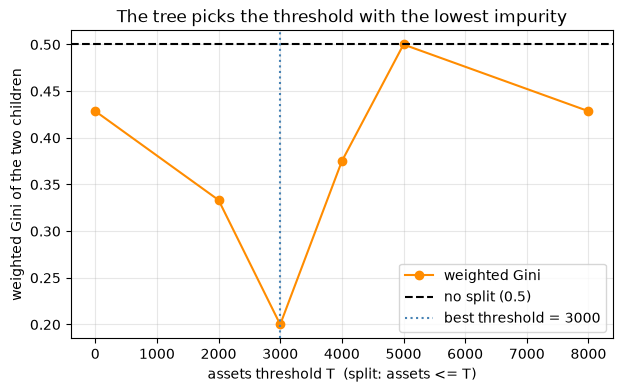

In [24]:
fig, ax = plt.subplots()

ax.plot(gini_table["threshold"], gini_table["weighted_gini"],
        marker="o", color="darkorange", label="weighted Gini")
ax.axhline(0.5, color="black", linestyle="--", label="no split (0.5)")
ax.axvline(3000, color="steelblue", linestyle=":", label="best threshold = 3000")

ax.set_xlabel("assets threshold T  (split: assets <= T)")
ax.set_ylabel("weighted Gini of the two children")
ax.set_title("The tree picks the threshold with the lowest impurity")
ax.legend()
plt.show()

### 6.3 More than one feature

With one feature we only had to compare thresholds. With several features we repeat
the same calculation for every feature and keep the overall best
(feature, threshold) pair.

Let us add a `debt` column to the toy data and compare the best split for each
feature.

In [25]:
data2 = [
    [8000, 3000, "default"],
    [2000, 1000, "default"],
    [0, 1000, "default"],
    [5000, 1000, "ok"],
    [5000, 1000, "ok"],
    [4000, 1000, "ok"],
    [9000, 500, "ok"],
    [3000, 2000, "default"],
]
df_example2 = pd.DataFrame(data2, columns=["assets", "debt", "status"])


def best_split(df, feature, target="status"):
    # Return (best threshold, weighted Gini) for one feature.
    best = None
    for T in sorted(df[feature].unique()):
        left = df[df[feature] <= T]
        right = df[df[feature] > T]
        if len(left) == 0 or len(right) == 0:
            continue

        score = (
            len(left) / len(df) * gini_impurity(left[target])
            + len(right) / len(df) * gini_impurity(right[target])
        )
        if best is None or score < best[1]:
            best = (T, score)
    return best


for feature in ["assets", "debt"]:
    threshold, score = best_split(df_example2, feature)
    print(f"{feature:>6}: best threshold = {threshold:>5}, weighted Gini = {score:.4f}")

assets: best threshold =  3000, weighted Gini = 0.2000
  debt: best threshold =  1000, weighted Gini = 0.3333


`assets <= 3000` wins (0.200 vs 0.333 for `debt <= 1000`), so the root split uses
`assets`. The tree then recurses:

- the left child (`assets <= 3000`) is pure, so it becomes a leaf predicting
  `default`;
- the right child (`assets > 3000`) is still mixed, so the same search runs again
  inside it, using the remaining rows and the remaining features.

This **greedy, recursive** procedure is the whole CART algorithm (Classification
and Regression Trees). It is greedy because each split is chosen to be best *right
now*; it never goes back to reconsider an earlier split. That is not guaranteed to
find the globally smallest tree, but it is fast and works well in practice.

> **Thresholds in practice.** We tried thresholds at the observed values. A real
> implementation sorts the values and only considers midpoints between consecutive
> distinct values (for example `3000.5`), because any threshold between two values
> produces the same split. scikit-learn then routes a row with `<= threshold` to the
> left. That is why the printed tree shows values like `<= 6.50` and `<= 862.50`.

### 6.4 When does the tree stop?

If we never stop, the tree keeps splitting until every leaf is pure. On real data
that means memorizing individual rows. We control this with **stopping criteria**,
which are exactly the hyperparameters we tune later:

| Parameter | What it controls | Effect of increasing it |
|---|---|---|
| `max_depth` | maximum splits on any root-to-leaf path | deeper = more complex, more overfitting |
| `min_samples_split` | minimum rows a node needs before it may split | larger = fewer splits |
| `min_samples_leaf` | minimum rows that must end up in each leaf | larger = smoother, less overfitting |
| `max_leaf_nodes` | maximum number of leaves in the whole tree | larger = more complex |
| `min_impurity_decrease` | minimum impurity improvement required to split | larger = fewer, more valuable splits |
| `ccp_alpha` | cost-complexity pruning strength | larger = more pruning |

The two we will tune are `max_depth` and `min_samples_leaf`, because they are
the easiest to understand:

- **`max_depth`** limits how many questions can be asked in a row. A depth-2 tree
  can only describe four groups; a depth-20 tree can describe a million.
- **`min_samples_leaf`** says "do not create a rule that applies to fewer than *k*
  people". This prevents a leaf that contains one unusual applicant and therefore
  memorizes noise.

Those two interact. A deep tree with a large minimum leaf size can still be
reasonable, which is why we tune them together rather than one at a time.

### 6.5 Why trees overfit — the bias–variance view

Every model makes two kinds of error:

- **Bias** — error from being too simple. A depth-1 tree (a single split) has high
  bias: it cannot represent "records AND seniority AND assets".
- **Variance** — error from being too sensitive to the particular training sample.
  A fully grown tree has high variance: if you replace 10% of the training rows, the
  splits near the bottom can change completely.

A single deep tree has low bias and high variance. It fits the training data
beautifully and generalizes poorly. The next two sections attack the variance:

- **Random forest** averages many deep trees → variance goes down.
- **Gradient boosting** adds many shallow trees → bias goes down, with careful
  regularization so variance does not explode.

## 7. Tuning a single decision tree

We now have the vocabulary to tune the tree properly. We will:

1. sweep `max_depth` and look at **train vs validation** AUC;
2. sweep `min_samples_leaf` at the most promising depths;
3. pick a combination and read the resulting tree.

The train/validation gap is the diagnostic tool. If both scores are low, the tree
underfits. If train is high and validation is low, it overfits. We want the
validation score to be as high as possible, not the training score.

### 7.1 Sweeping `max_depth`

In [26]:
depth_rows = []

for depth in [1, 2, 3, 4, 5, 6, 7, 10, 15, 20, None]:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)

    train_auc = roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1])
    val_auc = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])

    depth_rows.append({
        "max_depth": depth,
        "leaves": dt.get_n_leaves(),
        "train_auc": train_auc,
        "val_auc": val_auc,
    })

df_depth = pd.DataFrame(depth_rows)
df_depth.assign(max_depth=df_depth["max_depth"].astype("Int64")).round(4)

,max_depth,leaves,train_auc,val_auc
0,1,2,0.6283,0.6059
1,2,4,0.7055,0.6685
2,3,8,0.7761,0.7389
3,4,15,0.8164,0.7613
4,5,28,0.8434,0.7665
5,6,54,0.8745,0.7578
6,7,92,0.8996,0.7537
7,10,237,0.9640,0.6952
8,15,403,0.9985,0.6660
9,20,451,1.0000,0.6499


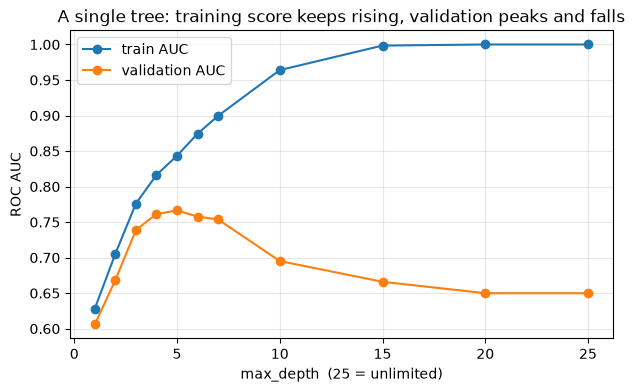

In [26]:
fig, ax = plt.subplots()

# For plotting, replace None (unlimited) with 25 so it appears on the right
plot_depths = df_depth["max_depth"].fillna(25)

ax.plot(plot_depths, df_depth["train_auc"], marker="o", label="train AUC")
ax.plot(plot_depths, df_depth["val_auc"], marker="o", label="validation AUC")
ax.set_xlabel("max_depth  (25 = unlimited)")
ax.set_ylabel("ROC AUC")
ax.set_title("A single tree: training score keeps rising, validation peaks and falls")
ax.legend()
plt.show()

**What the table and plot show**

- Depth 1 (a single split) reaches only **0.606** validation AUC. This is a very
  simple model — high bias.
- Validation AUC peaks at **depth 5** (**0.767**); depth 6 is already down to
  **0.758**.
- After that, training AUC keeps climbing toward **1.000**, but validation AUC
  **falls**. At unlimited depth it is back to **0.650**.
- The number of leaves explodes: 2 at depth 1, 54 at depth 6, 451 when unlimited.

The widening gap between the two curves *is* overfitting. The tree is using its
extra depth to memorize quirks of the training sample instead of learning patterns
that transfer.

### 7.2 Sweeping `min_samples_leaf`

The best depth-only model reaches **0.767** (depth 5). Adding more depth does not
help, because even a depth-6 tree can still create leaves with only one or two
people. Adding a minimum leaf size forces each rule to describe a meaningful group.

We scan a grid of depths and leaf sizes and store every validation AUC.

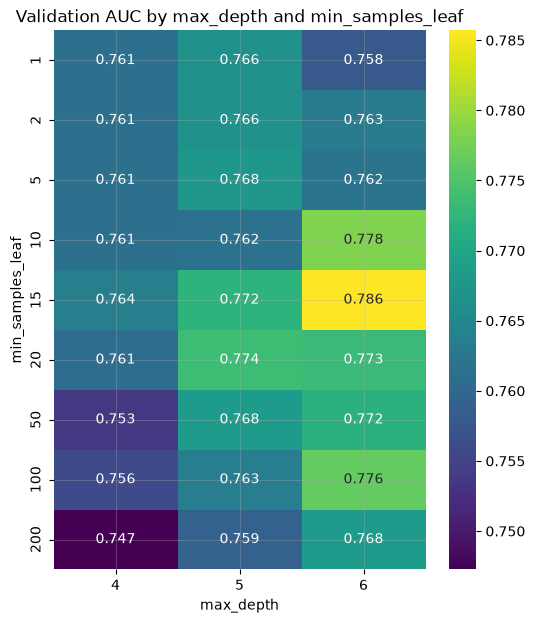

In [28]:
grid_rows = []

for depth in [4, 5, 6]:
    for leaf in [1, 2, 5, 10, 15, 20, 50, 100, 200]:
        dt = DecisionTreeClassifier(
            max_depth=depth, min_samples_leaf=leaf, random_state=1
        )
        dt.fit(X_train, y_train)

        val_auc = roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1])
        grid_rows.append({
            "max_depth": depth,
            "min_samples_leaf": leaf,
            "val_auc": val_auc,
        })

df_grid = pd.DataFrame(grid_rows)

pivot = df_grid.pivot(
    index="min_samples_leaf", columns="max_depth", values="val_auc"
)

plt.figure(figsize=(6, 7))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
plt.title("Validation AUC by max_depth and min_samples_leaf")
plt.xlabel("max_depth")
plt.ylabel("min_samples_leaf")
plt.show()

The heatmap is read like a map: brighter/yellower = better. Two things stand out:

- At `max_depth=6`, increasing `min_samples_leaf` from 1 to 15 **improves** AUC from
  **0.758 to 0.786**. The depth that looked overfit in Section 7.1 becomes the best
  tree once each leaf is required to contain at least 15 clients.
- At `min_samples_leaf=200` the trees are too constrained: depth 4 falls to 0.747
  and depth 5 to 0.759. Depth 6 recovers to 0.768, but that is still below its
  0.786 peak. The leaves are now too large to express local rules — underfitting.

This is the practical lesson: **hyperparameters interact**. Do not conclude "depth 6
is bad" from a sweep that fixed `min_samples_leaf=1`.

The best cell in this grid is `max_depth=6, min_samples_leaf=15`, with validation
AUC **0.786**. That is our single-tree model.

In [29]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15, random_state=1)
dt.fit(X_train, y_train)

val_pred_dt = dt.predict_proba(X_val)[:, 1]
print(f"single tree validation AUC: {roc_auc_score(y_val, val_pred_dt):.4f}")
print(f"leaves: {dt.get_n_leaves()}")

single tree validation AUC: 0.7857
leaves: 40


In [30]:
# max_depth here limits only how much of the tree is PRINTED, not the model.
print(export_text(
    dt,
    feature_names=list(dv.get_feature_names_out()),
    max_depth=3,
))

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- amount <= 862.50
|   |   |   |--- price <= 925.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- price >  925.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- amount >  862.50
|   |   |   |--- assets <= 8250.00
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- assets >  8250.00
|   |   |   |   |--- truncated branch of depth 2
|   |--- seniority >  6.50
|   |   |--- income <= 103.50
|   |   |   |--- assets <= 4500.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- assets >  4500.00
|   |   |   |   |--- class: 0
|   |   |--- income >  103.50
|   |   |   |--- time <= 33.00
|   |   |   |   |--- class: 0
|   |   |   |--- time >  33.00
|   |   |   |   |--- truncated branch of depth 3
|--- records=no >  0.50
|   |--- job=parttime <= 0.50
|   |   |--- income <= 74.50
|   |   |   |--- assets <= 4250.00
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |

The printed tree is truncated at three levels so it fits on the page; the real model
has six levels. Reading it is the same as before:

- the first split is still `records=no` (credit records are the strongest single
  signal);
- then the tree looks at `seniority`, `amount`, `price`, `assets`, `income`, and
  `job=parttime`;
- every leaf ends in a class, but it also stores a probability — the share of
  defaulters in that leaf among training rows.

The tree is a **piecewise-constant** model. Within each leaf, every applicant gets
the same predicted probability, no matter how different they are. That is both its
strength (simple, interpretable) and its weakness (it cannot express smooth
gradients like "the risk rises gradually with debt").

Trees also cannot **extrapolate**. If a new applicant has an income far above every
training income, the tree sends them down the same branch as the largest training
value, and the prediction stays inside the range of leaf values the tree has seen.
That is fine for ranking within the observed population, but it is a reason to be
careful when the applicant population shifts.

### 7.3 Which features did the tree use?

`feature_importances_` reports the **mean decrease in impurity** caused by each
feature, averaged over all the splits where it was used, weighted by the number of
rows that passed through those splits. The values are normalized to sum to 1.

In [31]:
importance = pd.Series(
    dt.feature_importances_, index=dv.get_feature_names_out()
).sort_values(ascending=False)

importance.head(10).round(4)

records=no      0.2442
income          0.1855
job=parttime    0.1729
assets          0.1226
seniority       0.1215
amount          0.0497
price           0.0302
expenses        0.0251
time            0.0190
age             0.0139
dtype: float64

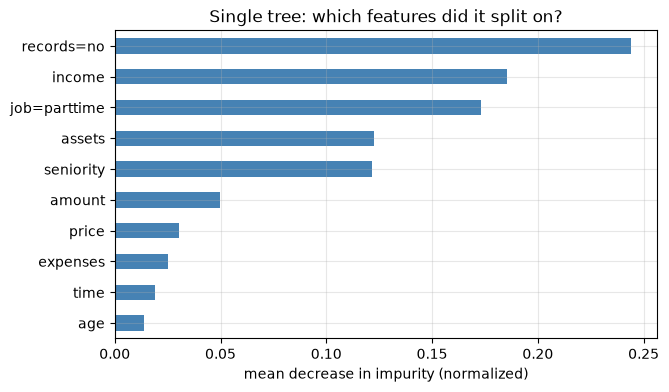

In [32]:
top = importance.head(10).sort_values()

plt.figure(figsize=(7, 4))
top.plot.barh(color="steelblue")
plt.xlabel("mean decrease in impurity (normalized)")
plt.title("Single tree: which features did it split on?")
plt.show()

The top features are `records=no`, `income`, `job=parttime`, `assets`, and
`seniority` — the same signals a credit analyst would look at, which is reassuring.

But **do not over-read these numbers**:

- They are computed on the **training** set, where the tree has already seen the
  labels.
- They are **biased toward features with many distinct values** (like `income` and
  `assets`), because such features offer more possible split points.
- When two features are **correlated**, the tree picks one and gives it all the
  credit; the other looks unimportant even if it carries the same information.
- They describe what *this tree* used, not what is causally important.

A more trustworthy, model-agnostic alternative is **permutation importance**, which
we will use on the final model in Section 13.6.

## 8. Ensembles: why many trees beat one tree

A fully grown single tree is a **high-variance** model: change a few training rows
and the lower splits can change completely. The idea of an ensemble is:

> If one expert is noisy, ask a room full of experts and average their answers.

Each expert (tree) makes different mistakes. If the mistakes were independent, the
average of `B` predictions would have variance `σ² / B` — much smaller than any
single predictor. In practice the trees are correlated (they see the same data), so
the reduction is smaller, but still substantial.

There are two big families of tree ensembles:

| Family | How it builds trees | Main effect | Example |
|---|---|---|---|
| **Bagging** | many trees in **parallel**, each on a random sample | reduces **variance** | random forest |
| **Boosting** | trees in **sequence**, each fixing the previous errors | reduces **bias** | gradient boosting, XGBoost |

This section is about bagging; Section 10 is about boosting.

### 8.1 The random forest algorithm

A random forest grows `B` decision trees and averages their predicted probabilities:

1. **Bootstrap the rows.** For each tree, draw `n` rows *with replacement* from the
   training set. On average, about **63%** of the original rows appear at least once;
   the rest are "out of bag" for that tree.
2. **Randomize the features.** At every split, consider only a random subset of
   `max_features` features instead of all of them. This is what makes the trees
   *different* from each other. If every tree saw every feature, they would tend to
   pick the same strongest split and be highly correlated.
3. **Grow each tree deep.** Individual trees are allowed to overfit; the averaging
   takes care of the variance.
4. **Average the probabilities.** For classification, average
   `P(default)` across all trees, then threshold the average.

The randomness has a purpose: **diversity**. Averaging ten identical trees gives
exactly the same prediction as one tree. Averaging ten *different* trees cancels
some of their individual errors.

### 8.2 Why more trees usually do not hurt

Adding trees cannot make the model much worse, because we are averaging more
estimates of the same quantity. The validation curve typically rises quickly and
then **plateaus**. The cost is compute and memory, not overfitting.

That is different from boosting, where adding too many trees *can* overfit. Keep
that distinction in mind.

### 8.3 The main hyperparameters

| Parameter | Meaning | Typical effect |
|---|---|---|
| `n_estimators` | number of trees | more = smoother, diminishing returns |
| `max_depth` | maximum depth per tree | deeper = lower bias, higher variance |
| `min_samples_leaf` | minimum rows per leaf | larger = smoother |
| `max_features` | features considered at each split | smaller = more diversity, more bias per tree |
| `bootstrap` | sample rows with replacement? | `False` = all rows, still random features |
| `n_jobs` | CPU cores to use | speed only, not accuracy |

The default `max_features` for classification is `sqrt(n_features)`. With 29 encoded
features that is about 5 — each split only looks at 5 of them. That sounds
restrictive, but it is exactly what decorrelates the trees.

## 9. Training a random forest

We will build up the forest in the same order as the course:

1. grow forests with more and more trees, keeping everything else default;
2. add `max_depth` and compare depths;
3. add `min_samples_leaf` and compare leaf sizes;
4. keep the best combination.

### 9.1 How many trees do we need?

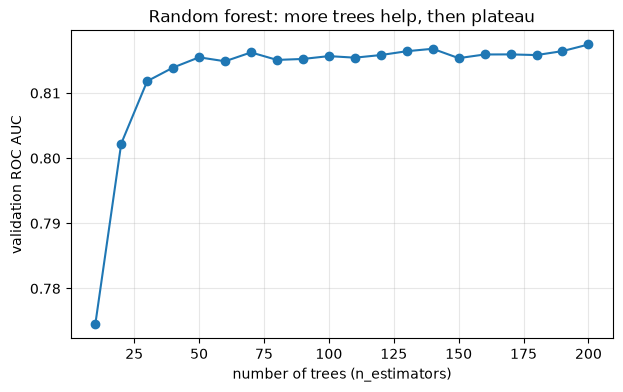

In [33]:
rf_rows = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(
        n_estimators=n, random_state=1, n_jobs=-1
    )
    rf.fit(X_train, y_train)

    val_auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
    rf_rows.append({"n_estimators": n, "val_auc": val_auc})

df_rf_n = pd.DataFrame(rf_rows)

plt.plot(df_rf_n["n_estimators"], df_rf_n["val_auc"], marker="o")
plt.xlabel("number of trees (n_estimators)")
plt.ylabel("validation ROC AUC")
plt.title("Random forest: more trees help, then plateau")
plt.show()

The curve jumps from **0.774** at 10 trees to about **0.816** at 50, then flattens.
By 200 trees we are at **0.817** with default (unlimited) depth. The exact plateau
value depends on the other hyperparameters, but the shape is universal: **the first
few trees matter most, and the last hundred barely move the score**.

This is why people often pick `n_estimators=200` or `300` and stop worrying about
it. The gain from 200 to 2,000 is usually negligible compared with the gain from
tuning depth or leaf size.

### 9.2 Tuning `max_depth`

Now we let each tree be shallower or deeper and see how the forest responds. We test
depths 5, 10, and 15, with the number of trees growing from 10 to 200.

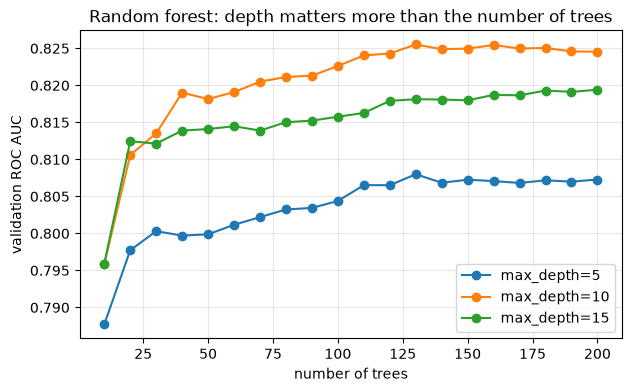

In [34]:
depth_rf_rows = []

for depth in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(
            n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1
        )
        rf.fit(X_train, y_train)

        val_auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
        depth_rf_rows.append({
            "max_depth": depth,
            "n_estimators": n,
            "val_auc": val_auc,
        })

df_rf_depth = pd.DataFrame(depth_rf_rows)

for depth in [5, 10, 15]:
    subset = df_rf_depth[df_rf_depth["max_depth"] == depth]
    plt.plot(subset["n_estimators"], subset["val_auc"], marker="o",
             label=f"max_depth={depth}")

plt.xlabel("number of trees")
plt.ylabel("validation ROC AUC")
plt.title("Random forest: depth matters more than the number of trees")
plt.legend()
plt.show()

Depth 10 is the best of the three (about **0.825** at 200 trees); depth 5 plateaus
around **0.807**, and depth 15 around **0.819**. Depth 15 is slightly worse than
depth 10 because the extra depth adds variance without adding useful signal.

Notice how flat each line is after ~50 trees. Once the forest has enough trees, its
score is controlled by **tree quality** (depth, leaf size, feature randomness), not
by the tree count.

### 9.3 Tuning `min_samples_leaf`

Same idea at the leaf level: how small may a leaf be? We test 1, 3, 5, 10, and 20
with depth fixed at 10.

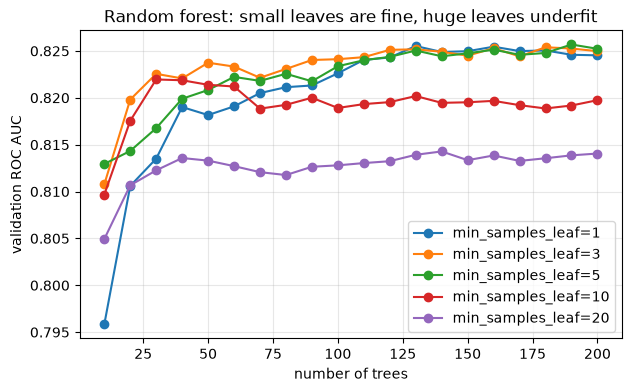

In [35]:
leaf_rf_rows = []

for leaf in [1, 3, 5, 10, 20]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(
            n_estimators=n,
            max_depth=10,
            min_samples_leaf=leaf,
            random_state=1,
            n_jobs=-1,
        )
        rf.fit(X_train, y_train)

        val_auc = roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1])
        leaf_rf_rows.append({
            "min_samples_leaf": leaf,
            "n_estimators": n,
            "val_auc": val_auc,
        })

df_rf_leaf = pd.DataFrame(leaf_rf_rows)

for leaf in [1, 3, 5, 10, 20]:
    subset = df_rf_leaf[df_rf_leaf["min_samples_leaf"] == leaf]
    plt.plot(subset["n_estimators"], subset["val_auc"], marker="o",
             label=f"min_samples_leaf={leaf}")

plt.xlabel("number of trees")
plt.ylabel("validation ROC AUC")
plt.title("Random forest: small leaves are fine, huge leaves underfit")
plt.legend()
plt.show()

Leaf sizes 1, 3, and 5 are essentially tied at **0.824–0.825**; 10 is slightly worse
(**0.820**), and 20 is clearly worse (**0.814**). A random forest tolerates small
leaves much better than a single tree, because averaging many trees cancels some of
the variance that a single tiny leaf would introduce. Still, making leaves huge
throws away local detail.

We will use **200 trees, depth 10, minimum leaf 5**, which scored **0.825** on
validation.

### 9.4 The final forest

In [36]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=1,
    n_jobs=-1,
)
rf.fit(X_train, y_train)

val_pred_rf = rf.predict_proba(X_val)[:, 1]
print(f"random forest validation AUC: {roc_auc_score(y_val, val_pred_rf):.4f}")

random forest validation AUC: 0.8252


The forest improves on the tuned single tree by about **0.04 AUC** (0.825 vs 0.786).
That is a large jump for a tabular problem, and it comes almost entirely from
**variance reduction**: each individual tree is still a mediocre, overfit model, but
their average is much more stable.

### 9.5 Forest feature importance

The forest also exposes `feature_importances_` — the average impurity decrease across
all trees. It is more stable than a single tree's ranking, but it has the same
conceptual caveats (training data, correlated features, bias toward many-valued
features).

In [37]:
rf_importance = pd.Series(
    rf.feature_importances_, index=dv.get_feature_names_out()
).sort_values(ascending=False)

rf_importance.head(10).round(4)

income          0.1507
seniority       0.1245
amount          0.0849
records=yes     0.0839
records=no      0.0832
assets          0.0777
price           0.0663
age             0.0579
job=parttime    0.0570
job=fixed       0.0479
dtype: float64

`income` and `seniority` now lead, followed by `amount`, `records=yes`,
`records=no`, and `assets`. The same core signals are there, but the values are
**spread more evenly** than in the single tree. That is expected: the forest has
200 trees, each using slightly different splits, so credit for a signal is shared.
When two features are correlated, different trees pick different ones, and both end
up with moderate importance instead of one winner.

Notice that `records=yes` and `records=no` are two one-hot columns of the **same**
original feature. Their importances (about 0.084 and 0.083) add up to roughly 0.17,
which is a large share of the total. Looking at one half of a one-hot feature in
isolation can therefore understate how much the feature matters.

This is a good moment to remember that **importance is not causation**. `amount`
being important means the size of the requested loan is associated with default in
this dataset; it does not mean that changing the loan amount would change a
client's risk.

## 10. Gradient boosting: learning from mistakes

Random forests build trees **in parallel** and average them. Gradient boosting
builds trees **in sequence**, and each new tree is trained to fix the mistakes of
the trees already in the ensemble.

The analogy: a student takes a practice exam, sees which questions were wrong,
studies those specific weaknesses, takes another exam, and repeats. Each round is
informed by the previous round's errors.

### 10.1 The algorithm in four lines

1. Start with a constant prediction — for logistic loss, the log-odds of the base
   rate. Call it $F_0$.
2. Compute the current error for every training row: $r_i = y_i - p_i$, where
   $p_i = \sigma(F(x_i))$ is the current predicted probability.
3. Fit a **small** regression tree to the errors $r_i$. This tree predicts the
   direction in which each row's score should move.
4. Add the tree to the model, scaled by a **learning rate** $\eta$:

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

Then go back to step 2 with the new predictions.

The residual $y_i - p_i$ is the negative gradient of the log-loss, which is why the
method is called **gradient** boosting. Each tree takes a small step downhill on the
loss surface.

### 10.2 Why the trees are shallow

In a random forest, each tree is deep and low-bias; averaging removes the variance.
In boosting, each tree is deliberately **weak** — usually depth 2–4. A weak learner
can only make a small correction, which is exactly what we want: many small,
carefully sequenced steps. If each tree were deep, one tree could fit the training
data almost perfectly, and the ensemble would overfit immediately.

The learning rate $\eta$ controls the step size:

- **small $\eta$** (0.01) → tiny steps, needs many trees, very smooth;
- **large $\eta$** (0.3) → big steps, learns fast, but can overshoot and overfit.

`n_estimators` (the number of trees) and `learning_rate` are therefore a **trade-off
pair**: halving the learning rate roughly doubles the number of trees you need.

### 10.3 Why this is not the same as a random forest

| | Random forest (bagging) | Gradient boosting |
|---|---|---|
| Tree order | independent, parallel | sequential, each depends on the previous |
| Tree size | deep | shallow (weak learners) |
| Main effect | reduces **variance** | reduces **bias** |
| Adding trees | plateaus, rarely hurts | can overfit if you add too many |
| Key risk | too few trees / too much depth | too many rounds / too high a learning rate |
| Typical tuning | `n_estimators`, `max_depth`, `max_features` | `learning_rate`, `n_estimators`, `max_depth` |

Boosting usually beats a random forest on tabular data, at the cost of being more
sensitive to hyperparameters and less parallelizable.

> **Where is XGBoost?** The course uses `xgboost`, which is a highly optimized
> implementation of gradient boosting. This repository does not depend on XGBoost,
> so we use scikit-learn's `GradientBoostingClassifier`. The concepts — shrinkage,
> tree depth, number of rounds, early stopping — are the same. Section 15 includes a
> parameter translation table if you want to follow the course code with XGBoost.

### 10.4 Train the first boosted model and watch it learn

We fit 300 trees with a learning rate of 0.1 and depth 3. `staged_predict_proba`
lets us evaluate the model **after each tree** without refitting: it yields the
predictions of the model with 1 tree, then 2 trees, and so on. That is how we can
plot the learning curve.

In [38]:
gb = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    random_state=1,
)
gb.fit(X_train, y_train)

train_curve = np.array([
    roc_auc_score(y_train, pred[:, 1])
    for pred in gb.staged_predict_proba(X_train)
])
val_curve = np.array([
    roc_auc_score(y_val, pred[:, 1])
    for pred in gb.staged_predict_proba(X_val)
])

iterations = np.arange(1, len(val_curve) + 1)
best_iter_gb = int(np.argmax(val_curve) + 1)

print(f"best iteration:      {best_iter_gb}")
print(f"validation AUC there:{val_curve[best_iter_gb - 1]:.4f}")
print(f"validation AUC at 300 trees: {val_curve[-1]:.4f}")
print(f"train AUC at 300 trees:      {train_curve[-1]:.4f}")

best iteration:      212
validation AUC there:0.8372
validation AUC at 300 trees: 0.8331
train AUC at 300 trees:      0.9645


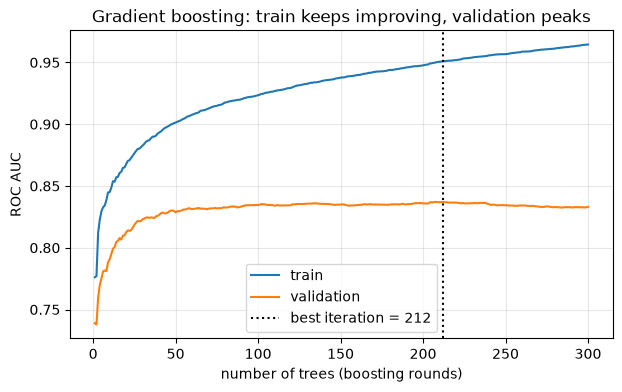

In [38]:
plt.plot(iterations, train_curve, label="train")
plt.plot(iterations, val_curve, label="validation")
plt.axvline(best_iter_gb, color="black", linestyle=":",
            label=f"best iteration = {best_iter_gb}")

plt.xlabel("number of trees (boosting rounds)")
plt.ylabel("ROC AUC")
plt.title("Gradient boosting: train keeps improving, validation peaks")
plt.legend()
plt.show()

**Reading the curve**

- Training AUC rises steadily — about **0.965** at 300 trees — and would keep
  climbing toward 1.000. Boosting can always fit the training data better by adding
  trees.
- Validation AUC rises quickly, peaks at **0.837** around **212 trees**, then
  slowly declines to **0.833** at 300.
- The peak is the point where the model has learned the signal but not yet started
  to memorize noise. Everything to the right is **overfitting**.

This is the boosting version of the depth sweep we did for a single tree. The
difference is that the complexity axis is now the **number of trees**, not the
depth.

In a real project we would stop at the peak. This technique is called **early
stopping**, and XGBoost/LightGBM implement it directly with
`early_stopping_rounds`. scikit-learn's `GradientBoostingClassifier` exposes
`n_iter_no_change` and `validation_fraction` if you prefer automatic stopping, but
here we selected the iteration explicitly on validation data so the process is
visible.

> **Important:** the best iteration is chosen on **validation**, never on test. If we
> picked the test iteration, our final test score would be optimistic.

## 11. Tuning gradient boosting

We will tune the three parameters that matter most:

| Parameter | Effect | Rule of thumb |
|---|---|---|
| `learning_rate` | step size per tree | 0.01–0.1; lower needs more trees |
| `max_depth` | complexity of each weak learner | 2–4 for tabular data |
| `min_samples_leaf` | minimum rows per leaf | 1–20; larger = smoother |

`n_estimators` is chosen together with the learning rate by watching the validation
curve.

### 11.1 Learning rate

We train 300 trees at four learning rates and record the best validation AUC and
where it occurs. This is a good example of why you cannot tune one parameter in
isolation: the optimal number of trees changes dramatically with the step size.

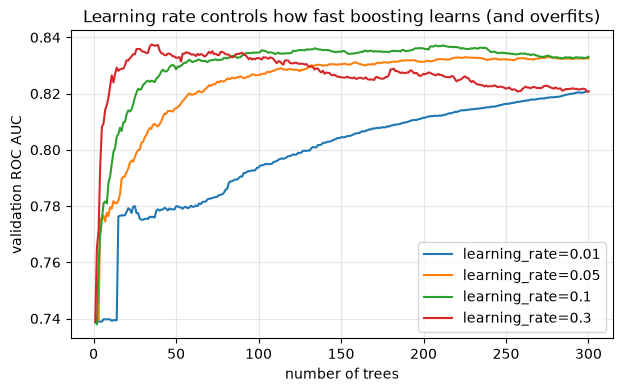

,learning_rate,best_iteration,best_val_auc,val_auc_at_300
0,0.01,300,0.8208,0.8208
1,0.05,277,0.8330,0.8325
2,0.10,212,0.8372,0.8331
3,0.30,35,0.8375,0.8207


In [39]:
lr_rows = []

plt.figure(figsize=(7, 4))
for lr in [0.01, 0.05, 0.1, 0.3]:
    model = GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=lr,
        max_depth=3,
        random_state=1,
    )
    model.fit(X_train, y_train)

    curve = np.array([
        roc_auc_score(y_val, pred[:, 1])
        for pred in model.staged_predict_proba(X_val)
    ])
    best_i = int(np.argmax(curve) + 1)

    lr_rows.append({
        "learning_rate": lr,
        "best_iteration": best_i,
        "best_val_auc": curve[best_i - 1],
        "val_auc_at_300": curve[-1],
    })

    plt.plot(np.arange(1, 301), curve, label=f"learning_rate={lr}")

plt.xlabel("number of trees")
plt.ylabel("validation ROC AUC")
plt.title("Learning rate controls how fast boosting learns (and overfits)")
plt.legend()
plt.show()

pd.DataFrame(lr_rows).round(4)

**What the table says**

| learning rate | best iteration | best validation AUC | validation at 300 |
|---:|---:|---:|---:|
| 0.01 | 300 | 0.821 | 0.821 |
| 0.05 | 277 | 0.833 | 0.833 |
| **0.10** | **212** | **0.837** | 0.833 |
| 0.30 | 35 | 0.838 | 0.821 |

- At `0.01`, the model is still improving at 300 trees: it needs many more rounds
  to reach the same place. It is smooth but expensive.
- At `0.3`, it reaches a similar peak after only **35 trees**, but then decays
  quickly to **0.821**. Large steps overshoot.
- `0.1` is the best compromise here: a high peak at a manageable number of trees.

The peak values of 0.837 and 0.838 are within noise of each other. The **shape** of
the curve is the real lesson: lower learning rates are more forgiving but slower;
higher rates need early stopping.

### 11.2 Tree depth

Now fix `learning_rate=0.1` and vary `max_depth`. For each depth we record the best
iteration and best validation AUC.

In [40]:
gb_depth_rows = []

for depth in [2, 3, 4, 6]:
    model = GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=depth,
        random_state=1,
    )
    model.fit(X_train, y_train)

    curve = np.array([
        roc_auc_score(y_val, pred[:, 1])
        for pred in model.staged_predict_proba(X_val)
    ])
    best_i = int(np.argmax(curve) + 1)
    gb_depth_rows.append({
        "max_depth": depth,
        "best_iteration": best_i,
        "best_val_auc": curve[best_i - 1],
        "val_auc_at_300": curve[-1],
    })

pd.DataFrame(gb_depth_rows).round(4)

,max_depth,best_iteration,best_val_auc,val_auc_at_300
0,2,195,0.8349,0.8326
1,3,212,0.8372,0.8331
2,4,100,0.8353,0.8222
3,6,62,0.8230,0.8132


- **Depth 2** is slightly underfit: it peaks at **0.835** and needs 195 trees.
- **Depth 3** is the best: **0.837** at 212 trees.
- **Depth 4** peaks a bit earlier (100 trees) at **0.835**, then decays.
- **Depth 6** peaks early (62 trees) at only **0.823** and decays to **0.813**.
  Deep trees memorize quickly, so boosting has to stop very early.

For boosting, depth 2–4 is the usual sweet spot on tabular data. The trees only need
to capture simple interactions; the sequence of trees supplies the complexity.

### 11.3 Minimum leaf size

`min_samples_leaf` plays the same role as in a single tree: it prevents rules that
apply to only a handful of people. Boosting is somewhat less sensitive to it
because each tree is already shallow, but it is still worth a quick check.

In [41]:
gb_leaf_rows = []

for leaf in [1, 5, 10, 20, 50]:
    model = GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=3,
        min_samples_leaf=leaf,
        random_state=1,
    )
    model.fit(X_train, y_train)

    curve = np.array([
        roc_auc_score(y_val, pred[:, 1])
        for pred in model.staged_predict_proba(X_val)
    ])
    best_i = int(np.argmax(curve) + 1)
    gb_leaf_rows.append({
        "min_samples_leaf": leaf,
        "best_iteration": best_i,
        "best_val_auc": curve[best_i - 1],
    })

pd.DataFrame(gb_leaf_rows).round(4)

,min_samples_leaf,best_iteration,best_val_auc
0,1,212,0.8372
1,5,149,0.8370
2,10,194,0.8354
3,20,184,0.8336
4,50,136,0.8344


The differences are small: **0.837** at leaf 1 and 5, **0.835** at 10, **0.834** at
20, **0.834** at 50. Unlike the single tree — where leaf size was the difference
between 0.758 and 0.786 — boosting is fairly robust here. That is because each tree
is already constrained to depth 3, so it cannot create extremely tiny leaves unless
the data forces it.

We will keep **`min_samples_leaf=1`** (the default) and spend our complexity budget
on depth and the number of rounds.

### 11.4 The final boosted model

Putting the tuning together: `learning_rate=0.1`, `max_depth=3`,
`min_samples_leaf=1`, and `n_estimators=212` — the best iteration found by the
learning curve. We fit it once and keep its validation predictions for the
comparison below.

In [42]:
gb_best = GradientBoostingClassifier(
    n_estimators=best_iter_gb,
    learning_rate=0.1,
    max_depth=3,
    min_samples_leaf=1,
    random_state=1,
)
gb_best.fit(X_train, y_train)

val_pred_gb = gb_best.predict_proba(X_val)[:, 1]

print(f"gradient boosting validation AUC: {roc_auc_score(y_val, val_pred_gb):.4f}")

gradient boosting validation AUC: 0.8372


### 11.5 The three models side by side

Let us collect the validation scores of everything we have built so far.

In [43]:
comparison = pd.DataFrame([
    {"model": "Handwritten rule", "val_auc": rule_auc},
    {"model": "Decision tree (depth 6, leaf 15)",
     "val_auc": roc_auc_score(y_val, val_pred_dt)},
    {"model": "Random forest (200 trees, depth 10, leaf 5)",
     "val_auc": roc_auc_score(y_val, val_pred_rf)},
    {"model": "Gradient boosting (212 trees, lr 0.1, depth 3)",
     "val_auc": roc_auc_score(y_val, val_pred_gb)},
]).sort_values("val_auc", ascending=False)

comparison.round(4)

,model,val_auc
3,"Gradient boosting (212 trees, lr 0.1, depth 3)",0.8372
2,"Random forest (200 trees, depth 10, leaf 5)",0.8252
1,"Decision tree (depth 6, leaf 15)",0.7857
0,Handwritten rule,0.4711


The ranking is clear:

| Model | Validation AUC |
|---|---:|
| Gradient boosting | **0.837** |
| Random forest | 0.825 |
| Single decision tree | 0.786 |
| Handwritten rule | 0.471 |

Each step buys something:

- the **tree** learns thresholds from data and beats the handwritten rule by a wide
  margin;
- the **forest** averages away a lot of the tree's variance (+0.04);
- **boosting** squeezes out another +0.01 by correcting residual errors in sequence.

The jump from rule to tree is about learning; the jump from tree to forest is about
variance; the jump from forest to boosting is about bias. That is the whole module
in one sentence.

## 12. The final model and an honest test

We have made all our choices on the validation set. Now we:

1. refit the chosen gradient-boosting model on **train + validation** (80% of the
   data), using the iteration count selected above;
2. evaluate it **once** on the untouched test set;
3. cross-validate on train + validation to see how stable the score is.

### Why refit on train + validation?

Validation data was there to help us choose hyperparameters. Once the choices are
frozen, those 891 rows are just more labeled data, and more data usually means a
better model. The test set stays untouched, so the final estimate is still honest.

### 12.1 Refit and evaluate

In [44]:
# y_full_train was created before the split; now drop the target from the features
del df_full_train["status"]

full_train_dicts = df_full_train.fillna(0).to_dict(orient="records")
test_dicts = df_test.fillna(0).to_dict(orient="records")

dv_full = DictVectorizer(sparse=False)
X_full_train = dv_full.fit_transform(full_train_dicts)
X_test = dv_full.transform(test_dicts)

gb_final = GradientBoostingClassifier(
    n_estimators=best_iter_gb,
    learning_rate=0.1,
    max_depth=3,
    random_state=1,
)
gb_final.fit(X_full_train, y_full_train)

test_pred = gb_final.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_pred)

print(f"training rows: {len(X_full_train)}")
print(f"test rows:     {len(X_test)}")
print(f"test ROC AUC:  {test_auc:.4f}")

training rows: 3563
test rows:     891
test ROC AUC:  0.8339


**Test ROC AUC = 0.834.** The validation estimate was 0.837, so the two agree
closely. That is what we want: a validation score that predicts the test score is a
trustworthy validation score.

### 12.2 How stable is that number? Cross-validation

A single train/validation split gives one estimate that depends on which rows
happened to land where. **K-fold cross-validation** repeats the experiment on
different splits:

1. divide train + validation into 5 folds of roughly equal size;
2. for each fold, train on the other 4 folds and validate on this one;
3. average the 5 scores and look at their spread.

We use `StratifiedKFold`, which keeps the default rate roughly the same in every
fold. With imbalanced data that matters: a plain `KFold` could produce a fold with
very few defaulters, making its AUC noisy.

It costs 5 model fits but gives a much better sense of uncertainty than one split.

In [45]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

cv_scores = cross_val_score(
    GradientBoostingClassifier(
        n_estimators=best_iter_gb,
        learning_rate=0.1,
        max_depth=3,
        random_state=1,
    ),
    X_full_train,
    y_full_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
)

print("fold AUCs:", np.round(cv_scores, 4))
print(f"mean: {cv_scores.mean():.4f}")
print(f"std:  {cv_scores.std():.4f}")

fold AUCs: [0.8211 0.8488 0.8507 0.8681 0.8163]
mean: 0.8410
std:  0.0195


The folds range from about **0.816 to 0.868**, with mean **0.841** and standard
deviation **0.020**. The test AUC of **0.834** sits comfortably inside that spread.

Two lessons:

- **Report the spread, not just the mean.** "0.841 ± 0.020" is more honest than
  "0.841"; a difference of 0.01 between two models may be noise.
- **A single split can mislead.** Our validation split gave 0.837, the CV mean gave
  0.841, and the test gave 0.834. All three are estimates of the same quantity, and
  they differ because the data is finite.

### 12.3 The confusion matrix at threshold 0.5

AUC judges the ranking. To make decisions we need a threshold. The default is 0.5:
predict `default` if `P(default) >= 0.5`.

In [46]:
threshold_05 = 0.5
test_pred_05 = (test_pred >= threshold_05).astype(int)

cm_test = confusion_matrix(y_test, test_pred_05)
tn, fp, fn, tp = cm_test.ravel()

print("confusion matrix [[TN, FP], [FN, TP]]:")
print(cm_test)
print(f"\nTN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"accuracy:  {accuracy_score(y_test, test_pred_05):.3f}")
print(f"precision: {precision_score(y_test, test_pred_05):.3f}")
print(f"recall:    {recall_score(y_test, test_pred_05):.3f}")
print(f"F1:        {f1_score(y_test, test_pred_05):.3f}")

confusion matrix [[TN, FP], [FN, TP]]:
[[566  66]
 [125 134]]

TN=566  FP=66  FN=125  TP=134
accuracy:  0.786
precision: 0.670
recall:    0.517
F1:        0.584


**How to read the four numbers**

|  | predicted ok | predicted default |
|---|---:|---:|
| **actual ok** | TN = 566 | FP = 66 |
| **actual default** | FN = 125 | TP = 134 |

- **TP = 134**: defaulters we correctly flagged.
- **FP = 66**: good clients we wrongly flagged. The bank loses their business.
- **FN = 125**: defaulters we let through. The bank loses the loan principal.
- **TN = 566**: good clients correctly approved.

At 0.5 the model is **conservative**: precision is **0.670** (two thirds of the
clients it flags really do default), but recall is only **0.517** — it misses about
half of the defaulters. Accuracy is **0.786**, versus a 0.709 "always ok" baseline.
Accuracy looks decent; the recall tells the more important story.

Whether missing half the defaulters is acceptable depends entirely on the **cost of
a mistake**, which is the next section.

## 13. From probability to decision: choosing a threshold

A classifier does not decide anything by itself. It produces a probability, and
**we** choose the cutoff. The cutoff is a business decision, not a property of the
model.

Two rules of thumb:

- **Lower the threshold** → flag more clients → recall rises, precision falls.
- **Raise the threshold** → flag fewer clients → precision rises, recall falls.

There is no universally "correct" threshold. There is only a threshold that matches
the relative cost of the two errors.

### 13.1 Precision, recall, and F1 across thresholds

We choose the threshold on **validation** data, then apply it to test. Choosing it
on test would be cheating: we would be fitting the threshold to the exam.

In [47]:
thresholds = np.arange(0.05, 0.91, 0.01)
threshold_rows = []

for t in thresholds:
    pred = (val_pred_gb >= t).astype(int)
    tn_v, fp_v, fn_v, tp_v = confusion_matrix(y_val, pred).ravel()

    threshold_rows.append({
        "threshold": t,
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred),
        "f1": f1_score(y_val, pred),
        "tp": tp_v,
        "fp": fp_v,
        "fn": fn_v,
        "tn": tn_v,
    })

df_thresholds = pd.DataFrame(threshold_rows)
best_f1_row = df_thresholds.loc[df_thresholds["f1"].idxmax()]

print("best F1 on validation:")
print(best_f1_row.round(3).to_string())

best F1 on validation:
threshold      0.320
precision      0.635
recall         0.688
f1             0.661
tp           181.000
fp           104.000
fn            82.000
tn           524.000


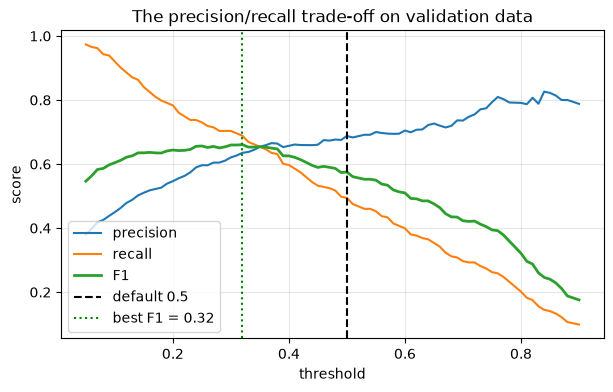

In [48]:
plt.plot(df_thresholds["threshold"], df_thresholds["precision"],
         label="precision")
plt.plot(df_thresholds["threshold"], df_thresholds["recall"],
         label="recall")
plt.plot(df_thresholds["threshold"], df_thresholds["f1"],
         label="F1", linewidth=2)

plt.axvline(0.5, color="black", linestyle="--", label="default 0.5")
plt.axvline(best_f1_row["threshold"], color="green", linestyle=":",
            label=f"best F1 = {best_f1_row['threshold']:.2f}")

plt.xlabel("threshold")
plt.ylabel("score")
plt.title("The precision/recall trade-off on validation data")
plt.legend()
plt.show()

The F1-optimal threshold on validation is **0.32**, where precision is **0.635**,
recall is **0.688**, and F1 is **0.661**. Compare that with 0.5 (precision 0.688,
recall 0.494, F1 0.575): moving the threshold down catches many more defaulters and
gives up relatively little precision.

### 13.2 Apply the chosen threshold to the test set

Now — and only now — we use the test set once, with the threshold chosen on
validation.

In [49]:
chosen_threshold = float(best_f1_row["threshold"])
test_pred_chosen = (test_pred >= chosen_threshold).astype(int)

tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_test, test_pred_chosen).ravel()

print(f"threshold = {chosen_threshold:.2f}")
print(f"TN={tn_c}  FP={fp_c}  FN={fn_c}  TP={tp_c}")
print(f"accuracy:  {accuracy_score(y_test, test_pred_chosen):.3f}")
print(f"precision: {precision_score(y_test, test_pred_chosen):.3f}")
print(f"recall:    {recall_score(y_test, test_pred_chosen):.3f}")
print(f"F1:        {f1_score(y_test, test_pred_chosen):.3f}")

threshold = 0.32
TN=510  FP=122  FN=77  TP=182
accuracy:  0.777
precision: 0.599
recall:    0.703
F1:        0.647


On the test set the same threshold gives **precision 0.599, recall 0.703, F1 0.647**.
The scores differ from validation because the test set is a different sample of
clients — this is normal sampling variation, and it is why we report both validation
and test results.

The big picture: lowering the threshold from 0.5 to 0.32 raises recall from **0.52**
to **0.70**. The model now catches about 70% of defaulters instead of half, at the
cost of flagging more good clients. Which is better depends on the cost of a
default.

### 13.3 The cost of mistakes

Let us make the trade-off concrete. Suppose:

- approving a client who defaults costs **10 units** (the lost principal);
- rejecting a good client costs **1 unit** (the lost profit).

The expected cost at a given threshold is:

$$\text{cost} = 10 \times FN + 1 \times FP$$

We can compute this for every threshold on the validation set and pick the cheapest.

In [49]:
COST_FN = 10   # approving a future defaulter
COST_FP = 1    # rejecting a good client

df_thresholds["cost"] = (
    COST_FN * df_thresholds["fn"] + COST_FP * df_thresholds["fp"]
)

best_cost_row = df_thresholds.loc[df_thresholds["cost"].idxmin()]
cost_at_05 = df_thresholds.loc[
    (df_thresholds["threshold"] - 0.5).abs().idxmin(), "cost"
]

print("cheapest threshold on validation:")
print(best_cost_row.round(3).to_string())
print(f"\ncost at threshold 0.50: {cost_at_05:.0f}")
print(f"cost at threshold {best_cost_row['threshold']:.2f}: {best_cost_row['cost']:.0f}")

cheapest threshold on validation:
threshold      0.070
precision      0.418
recall         0.962
f1             0.583
tp           253.000
fp           352.000
fn            10.000
tn           276.000
cost         452.000

cost at threshold 0.50: 1389
cost at threshold 0.07: 452


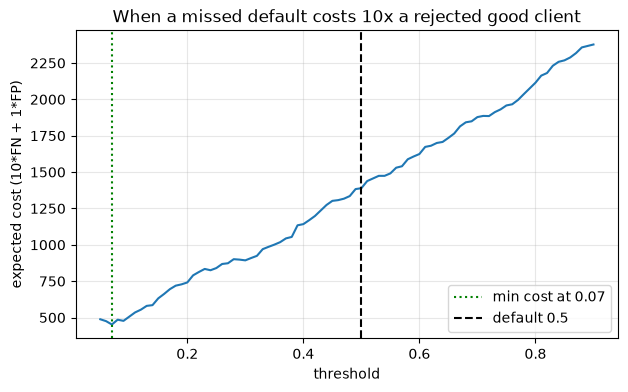

In [51]:
plt.plot(df_thresholds["threshold"], df_thresholds["cost"])
plt.axvline(best_cost_row["threshold"], color="green", linestyle=":",
            label=f"min cost at {best_cost_row['threshold']:.2f}")
plt.axvline(0.5, color="black", linestyle="--", label="default 0.5")

plt.xlabel("threshold")
plt.ylabel("expected cost (10*FN + 1*FP)")
plt.title("When a missed default costs 10x a rejected good client")
plt.legend()
plt.show()

With a 10:1 cost ratio, the cheapest threshold is **0.07**, not 0.5. At that point
the model flags about **68%** of applicants: recall is **0.962** (it catches 96% of
defaulters), precision is **0.418**, and the total cost is **452** versus **1,389**
at 0.5 — less than a third.

This is not a mathematical curiosity. It is the correct behavior when approving a
bad loan is ten times more expensive than rejecting a good one. Banks often combine
such a low threshold with a **manual review** step: flag broadly with the model,
then let a human collect more information before the final decision.

There are constraints the formula ignores:

- **capacity** — a review team can only process so many applications per day;
- **regulation and fairness** — a model may not use protected attributes, and the
  error rates may need to be similar across groups;
- **customer relationship** — rejecting a good client has a long-term cost beyond
  one lost loan.

So the cost curve narrows the choice; it does not make the decision for you.

### 13.4 The ROC curve

The ROC curve shows the full ranking trade-off: true positive rate (recall) against
false positive rate, over every possible threshold. The area under it is the AUC we
have been optimizing.

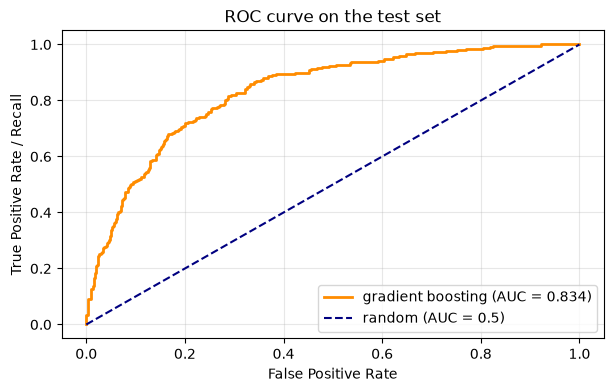

In [52]:
fpr, tpr, _ = roc_curve(y_test, test_pred)

plt.plot(fpr, tpr, color="darkorange", linewidth=2,
         label=f"gradient boosting (AUC = {test_auc:.3f})")
plt.plot([0, 1], [0, 1], color="navy", linestyle="--", label="random (AUC = 0.5)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC curve on the test set")
plt.legend(loc="lower right")
plt.show()

The curve bows well above the diagonal, which is what an AUC of 0.834 looks like. The
"elbow" near the top-left is where you get a lot of recall for little extra false
positive rate; that is often a good operating region.

### 13.5 Is the model calibrated?

AUC only cares about **ranking**. A separate question is whether the probabilities
are **calibrated**: when the model says "20% chance of default", do about 20% of
such clients actually default?

We can check by grouping test predictions into bins and plotting the average
predicted probability against the observed default rate in each bin. A perfectly
calibrated model lies on the diagonal.

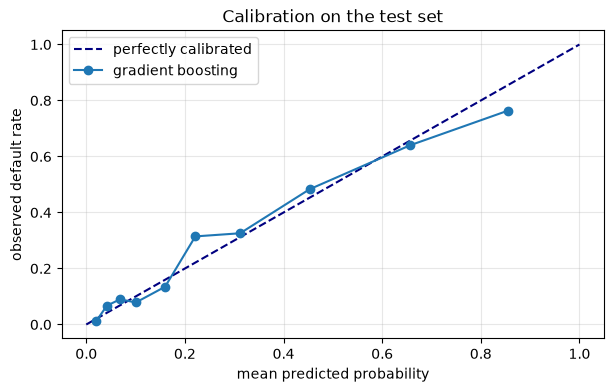

Brier score: 0.1464
mean predicted: 0.2886
observed rate:  0.2907


In [53]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

prob_true, prob_pred = calibration_curve(
    y_test, test_pred, n_bins=10, strategy="quantile"
)

plt.plot([0, 1], [0, 1], linestyle="--", color="navy", label="perfectly calibrated")
plt.plot(prob_pred, prob_true, marker="o", label="gradient boosting")

plt.xlabel("mean predicted probability")
plt.ylabel("observed default rate")
plt.title("Calibration on the test set")
plt.legend()
plt.show()

print("Brier score:", round(brier_score_loss(y_test, test_pred), 4))
print("mean predicted:", round(test_pred.mean(), 4))
print("observed rate: ", round(y_test.mean(), 4))

The curve is close to the diagonal, and the average prediction (**0.289**) is almost
exactly the observed default rate (**0.291**). The highest-risk bin is somewhat
overpredicted (about 0.86 predicted vs 0.76 observed), which is common with small
samples at the extremes.

The **Brier score** is the mean squared error of the probabilities; lower is better.
Here it is **0.146**. For reference, always predicting the base rate would give
about `0.29 * 0.71 ≈ 0.206`, so the model's probabilities are informative, not just
its ranking.

Calibration matters when you use the probability itself — for pricing a loan,
computing expected loss, or comparing against a fixed risk appetite. If you only use
the score to rank applicants, calibration is less important than AUC.

### 13.6 Permutation importance: which features does the model rely on?

Impurity importance (Sections 7 and 9) is computed on training data and is biased
toward features with many possible split points. **Permutation importance** asks a
different, more honest question:

> If I randomly shuffle one feature, how much does the model's validation AUC drop?

If shuffling a feature destroys performance, the model relies on it. If shuffling
changes nothing, the feature was not contributing (or another correlated feature
compensates for it).

In [54]:
perm = permutation_importance(
    gb_best,
    X_val,
    y_val,
    n_repeats=10,
    random_state=1,
    scoring="roc_auc",
    n_jobs=-1,
)

perm_df = pd.DataFrame({
    "feature": dv.get_feature_names_out(),
    "importance": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("importance", ascending=False)

perm_df.head(12).round(4)

,feature,importance,std
1,amount,0.0830,0.0057
12,income,0.0598,0.0072
24,price,0.0437,0.0049
2,assets,0.0364,0.0077
27,seniority,0.0345,0.0083
25,records=no,0.0222,0.0044
16,job=parttime,0.0194,0.0057
4,expenses,0.0131,0.0017
26,records=yes,0.0120,0.0029
0,age,0.0085,0.0041


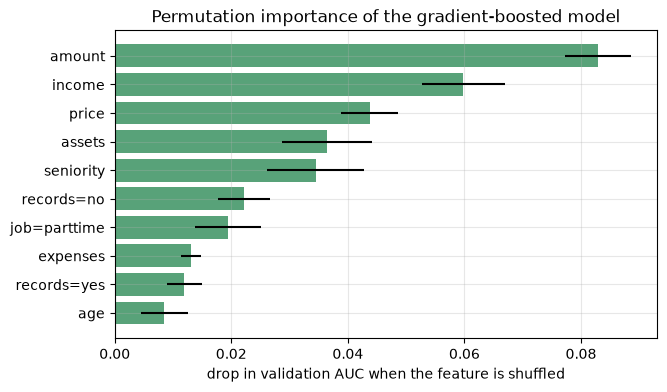

In [55]:
top_perm = perm_df.head(10).sort_values("importance")

plt.figure(figsize=(7, 4))
plt.barh(top_perm["feature"], top_perm["importance"],
         xerr=top_perm["std"], color="seagreen", alpha=0.8)
plt.xlabel("drop in validation AUC when the feature is shuffled")
plt.title("Permutation importance of the gradient-boosted model")
plt.show()

The top features are **`amount`**, **`income`**, **`price`**, **`assets`**, and
**`seniority`**, followed by `records=no` and `job=parttime`.

This ranking **disagrees** with the single tree's impurity importance, which put
`records=no`, `income`, and `job=parttime` on top. Neither list is "wrong"; they
answer different questions:

- Impurity importance asks *how much a feature reduced impurity inside the training
  trees*. It is biased toward features with many unique values and can over-credit a
  feature that was used for one big split.
- Permutation importance asks *how much the trained model's validation performance
  depends on a feature*. It is model-agnostic and measured on unseen data, but it
  can under-credit correlated features: if `income` and `assets` carry similar
  information, shuffling `income` leaves `assets` available, so the drop is small.

Two practical rules:

1. Use permutation importance when you want to know what the **model relies on**.
2. Use several methods, and be suspicious of any single importance ranking. If a
   feature matters for the business, the best test is still an experiment or a
   careful causal analysis, not an importance plot.

## 14. Summary

### 14.1 The journey in one table

| Model | How it works | Validation AUC | Test AUC |
|---|---|---:|---:|
| Handwritten rule | human-written if/else | 0.471 | — |
| Decision tree | one tree, depth 6, min leaf 15 | 0.786 | — |
| Random forest | 200 trees, depth 10, averaged | 0.825 | — |
| Gradient boosting | 212 shallow trees, sequential | **0.837** | **0.834** |

The final model was refit on train + validation (3,563 rows) and evaluated once on
891 held-out clients.

### 14.2 The concepts, in one line each

| Concept | One-line explanation |
|---|---|
| **Decision tree** | a flowchart of if/else questions learned from data |
| **Impurity (Gini)** | how mixed a group is; 0 = pure, 0.5 = 50/50 |
| **Split search** | try every feature and threshold; keep the purest split |
| **Greedy recursion** | choose the best split now, then repeat in each child |
| **Overfitting** | fitting the training noise; train AUC high, validation low |
| **`max_depth`** | maximum number of questions in a row |
| **`min_samples_leaf`** | minimum number of people a rule must cover |
| **Bagging** | many models in parallel on random samples, then average |
| **Random forest** | bagging + random feature subsets at each split |
| **Boosting** | models in sequence, each correcting the previous errors |
| **Learning rate** | how much of each new tree to add; small = slow and smooth |
| **Early stopping** | stop adding trees when validation stops improving |
| **ROC AUC** | probability that a random positive is ranked above a random negative |
| **Threshold** | the probability cutoff that turns scores into decisions |
| **Calibration** | do predicted probabilities match observed frequencies? |
| **Permutation importance** | how much AUC drops when a feature is shuffled |

### 14.3 The five ideas worth remembering

1. **A tree is a greedy, recursive splitter.** It does not plan ahead; it picks the
   best split at each node and repeats. That is fast and surprisingly effective.
2. **A single tree faces a bias–variance trade-off.** Deep trees have low bias and
   high variance; shallow trees have high bias and low variance. `max_depth` and
   `min_samples_leaf` are the two main dials.
3. **Bagging reduces variance, boosting reduces bias.** A random forest averages
   many independent deep trees; gradient boosting adds shallow trees that fix the
   current residual.
4. **Tune on validation, test once.** The test score is only honest if you did not
   use it to make choices. Report cross-validation spread, not just a single number.
5. **A threshold is a business decision.** ROC AUC ranks; the threshold decides.
   Choose it from the relative cost of false positives and false negatives, then
   check capacity, fairness, and regulation.

### 14.4 Common mistakes to avoid

- **Reporting accuracy on an imbalanced target.** 72% accuracy can mean zero
  defaulters caught. Always show the confusion matrix and recall.
- **Tuning on the test set.** Every comparison belongs on validation or inside
  cross-validation.
- **Filling missing values with 0 without thinking.** For income, 0 is a meaningful
  value, not "unknown". Consider a median imputer plus a missingness indicator.
- **Leaving the target in `X`.** Copy `y` first, then delete the target column.
- **Reading one-hot tree text literally.** `records=no <= 0.5` means "not
  records=no", i.e. records=yes. It is easy to invert a rule by mistake.
- **Treating feature importance as causation.** Importance says the model uses a
  feature; it does not say changing the feature changes the outcome.
- **Comparing models on different splits.** Use the same `random_state` and the same
  preprocessing for a fair comparison.
- **Assuming more trees always help boosting.** They help until validation peaks;
  after that they overfit. A random forest is the opposite: more trees rarely hurt.

## 15. Exercises and further exploration

These are ordered from "change one line" to "build something new". Try them in a
copy of the notebook so you do not lose the working results.

### Warm-up

1. **Change the split seed.** Set `RANDOM_STATE = 42` and rerun. How much does the
   test AUC move? Compare the movement with the cross-validation standard deviation
   (±0.020). Is the difference meaningful?
2. **Change the threshold.** Pick a threshold of 0.2 and 0.7 on validation. What
   happens to precision, recall, and the number of flagged clients? Which would you
   choose if a missed default costs 20× a rejected good client?
3. **Read the tree.** Print the full depth-2 tree and translate every path into a
   sentence. Which path do you find most plausible? Which is least plausible?

### Data preparation

4. **Better missing-value handling.** Add an indicator column `income_missing`,
   `assets_missing`, and `debt_missing`, then fill the numeric columns with the
   **training median** instead of 0. Does validation AUC improve? Does the tree use
   the indicator columns?
5. **Feature engineering.** Add ratios such as `debt / (income + 1)`,
   `amount / (price + 1)`, and `expenses / (income + 1)`. Use a small constant to
   avoid division by zero. Do they improve the model? Are they available at
   decision time (no leakage)?
6. **Drop a feature.** Remove `records` and retrain. How much AUC do you lose? Does
   that match the importance ranking?

### Models

7. **Tune the forest further.** Try `max_features` values of `0.3`, `0.5`, and
   `"sqrt"`, and `bootstrap=True/False`. Does the forest beat 0.825?
8. **Try `ExtraTreesClassifier`.** It chooses thresholds randomly instead of
   optimally. It is faster and sometimes more regularized. Compare its validation
   AUC with the random forest.
9. **Try `HistGradientBoostingClassifier`.** It is scikit-learn's fast,
   histogram-based boosting implementation and it handles `NaN` natively. Compare
   speed and AUC with `GradientBoostingClassifier`.
10. **Try XGBoost.** Install it (`uv add xgboost` or `pip install xgboost`) and
    reproduce the final model. Use the translation table below.

### Evaluation and decisions

11. **Cost-sensitive threshold.** Rerun the cost analysis with FN:FP ratios of 2:1,
    5:1, and 20:1. How does the optimal threshold move? What happens to the number
    of clients needing manual review?
12. **Capacity constraint.** Suppose the review team can handle only 20% of
    applicants. Find the highest threshold that flags at most 20% of validation
    clients. What recall do you get?
13. **Calibration.** Wrap the model in
    `CalibratedClassifierCV(..., method="isotonic")` and compare the calibration
    curve and Brier score. Does calibration change AUC? (It should not change
    ranking much.)
14. **Permutation importance vs impurity importance.** Repeat permutation
    importance for the random forest. Which features disagree with the forest's
    `feature_importances_`? Why?

### Going further

15. **Regression trees.** Use `DecisionTreeRegressor` to predict `price` from the
    other features (treat `price` as the target). Compare with a linear regression.
    Which handles non-linearities better? Which is more interpretable?
16. **Nested cross-validation.** If you tune many hyperparameters, the validation
    score itself becomes optimistic. Learn about nested CV and estimate how much
    optimism there is in this notebook's 0.837.
17. **SHAP values.** Use the `shap` library to explain individual predictions. Can
    you explain why one specific client was flagged?

### XGBoost translation table

If you follow the course's XGBoost code, these are the equivalents:

| XGBoost parameter | scikit-learn equivalent | Meaning |
|---|---|---|
| `eta` | `learning_rate` | shrinkage per tree |
| `max_depth` | `max_depth` | depth of each weak tree |
| `min_child_weight` | `min_samples_leaf` (roughly) | minimum leaf size |
| `num_boost_round` | `n_estimators` | number of trees |
| `subsample` | `subsample` | fraction of rows per tree |
| `colsample_bytree` | `max_features` | fraction of features per tree |
| `lambda` | `l2_regularization` (HistGradientBoosting) | L2 regularization |
| `alpha` | no direct equivalent in classic GB | L1 regularization |
| `objective="binary:logistic"` | `loss="log_loss"` | binary classification loss |
| `eval_metric="auc"` | `scoring="roc_auc"` | evaluation metric |
| `early_stopping_rounds` | `n_iter_no_change` | stop when validation stops improving |

XGBoost also handles missing values natively, uses second-order gradients, and is
optimized for speed. The conceptual model — shallow trees added sequentially with a
shrinking learning rate — is exactly what you implemented above.

## References

- Module 6, *Machine Learning Zoomcamp*:
  <https://github.com/DataTalksClub/machine-learning-zoomcamp/tree/main/06-trees>
- Dataset and original analysis, Gaston Sanchez:
  <https://github.com/gastonstat/CreditScoring>
- scikit-learn decision trees:
  <https://scikit-learn.org/stable/modules/tree.html>
- scikit-learn ensembles:
  <https://scikit-learn.org/stable/modules/ensemble.html>
- scikit-learn `GradientBoostingClassifier`:
  <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html>
- XGBoost parameter guide:
  <https://xgboost.readthedocs.io/en/latest/parameter.html>
- "The Elements of Statistical Learning", chapters 9–10 (trees, boosting):
  <https://hastie.su.domains/ElemStatLearn/>